In [15]:
from ete3 import Tree, TreeStyle, NodeStyle, TextFace  # add_face_to_node, AttrFace, RectFace, SeqMotifFace
from pathlib import Path
#import requests
#import re
from Bio import SeqIO
import importlib
import unstudied_gene_tools as ugt

importlib.reload(ugt)


# Base directory for all project data
BASE_DIR = Path(r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes")
PUG_ENZYME_DIR = Path(r"G:\.shortcut-targets-by-id\0B3ejcGO9fA5eYXlHMW9tekVERmc\JB labs documents\Updated_JB_documents_2019\JB LAB_Projects\PUG_PPIs")

In [16]:
# Concatenate panther family fastas per gene, keeping only species in species_dict

PANTHER_DIR = PUG_ENZYME_DIR / "bioinformatics" / "panther"

species_dict = {"Schizosaccharomyces pombe": ("fission_yeast","SCHPO", "Fungi"),
    "Schizosaccharomyces japonicus": ("japonicus_yeast","SCHJY", "Fungi"),
    "Saccharomyces cerevisiae": ("budding_yeast","YEAST", "Fungi"),
    "Yarrowia lipolytica": ("yarrowia_yeast","YARLI", "Fungi"),
    "Candida albicans": ("candida_yeast","CANAL", "Fungi"),
    "Neurospora crassa": ("neurospora","NEUCR", "Fungi"),
    "Homo sapiens": ("human","HUMAN", "Metazoa"),
    "Mus musculus": ("mouse","MOUSE", "Metazoa"),
    "Rattus norvegicus": ("rat","RAT", "Metazoa"),
    "Danio rerio": ("zebrafish","DANRE", "Metazoa"),
    "Xenopus laevis": ("frog","XENLA", "Metazoa"),
    "Drosophila melanogaster": ("fruit_fly","DROME", "Metazoa"),
    "Caenorhabditis elegans": ("worm","WORM", "Metazoa"),
    "Arabidopsis thaliana": ("arabidopsis","ARATH", "Plantae"),
    "Zea mays": ("maize","MAIZE", "Plantae"),
    "Chlamydomonas reinhardtii": ("green_algae","CHLRE", "Plantae"),
    "Marchantia polymorpha": ("liverwort","MARPO", "Plantae"),
    "Bacillus subtilis": ("b_subtilis","BACSU", "Bacteria"),
    "Escherichia coli": ("e_coli","ECOLI", "Bacteria"), 
    "Sulfolobus solfataricus": ("s_solfataricus(archaeon)","SACS2", "Archaea"),
    "Thermococcus kodakarensis": ("t_kodakarensis(archaeon)","THEKO", "Archaea")
}

panther_families = {"SPBC115.03":["PTHR22604","PTHR42840", "PTHR43708", "PTHR43818"], 
                    "SPAPB1A10.12c":["PTHR13878","PTHR43762"]}

for gene, families in panther_families.items():
    ugt.extract_model_proteins_from_panther_families(PANTHER_DIR, gene, families, species_dict)

#Add additional proteins to the concatenated file:

additional_species = {"Sphingobioum sp.":("sphingobium","SPHSK", "Bacteria"), 
                      "Azospirillum brasilense":("azospirillum","AZOBR", "Bacteria")}
#goi:[(new_header, fasta_filename), ...]
fastas_to_add = {
    "SPBC115.03": [("SPHSK|Gene=LIGC_SPHSK|UniProtKB=Q9KWL3", PUG_ENZYME_DIR / "bioinformatics" / "SPBC115.03" / "Q9KWL3.fasta"), ("AZOBR|Gene=ARAA_AZOBR|UniProtKB=Q53TZ2", PUG_ENZYME_DIR / "bioinformatics" / "SPBC115.03" / "Q53TZ2.fasta")]
}

# Append the extra sequences to each gene's concatenated fasta (the file is rebuilt above on every run, so no duplicates)
for gene, extra_fastas in fastas_to_add.items():
    concat_path = PANTHER_DIR / gene.replace(".", "_") / "concatenated_families.fasta"
    records = list(SeqIO.parse(str(concat_path), "fasta"))
    existing_ids = {r.id for r in records}
    for new_header, fasta in extra_fastas:
        for rec in SeqIO.parse(str(fasta), "fasta"):
            # Replace the UniProt header with the PantherDB-style header
            rec.id = new_header
            rec.name = new_header
            rec.description = ""
            if rec.id not in existing_ids:
                records.append(rec)
                existing_ids.add(rec.id)
    SeqIO.write(records, str(concat_path), "fasta")
    print(f"{gene}: {len(records)} sequences in {concat_path}")


SPBC115.03 PTHR22604: kept 14 of 81 sequences
SPBC115.03 PTHR42840: kept 17 of 133 sequences
SPBC115.03 PTHR43708: kept 14 of 45 sequences
SPBC115.03 PTHR43818: kept 12 of 109 sequences
Wrote 57 sequences to G:\.shortcut-targets-by-id\0B3ejcGO9fA5eYXlHMW9tekVERmc\JB labs documents\Updated_JB_documents_2019\JB LAB_Projects\PUG_PPIs\bioinformatics\panther\SPBC115_03\concatenated_families.fasta
SPAPB1A10.12c PTHR13878: kept 45 of 721 sequences
SPAPB1A10.12c PTHR43762: kept 17 of 112 sequences
Wrote 62 sequences to G:\.shortcut-targets-by-id\0B3ejcGO9fA5eYXlHMW9tekVERmc\JB labs documents\Updated_JB_documents_2019\JB LAB_Projects\PUG_PPIs\bioinformatics\panther\SPAPB1A10_12c\concatenated_families.fasta
SPBC115.03: 59 sequences in G:\.shortcut-targets-by-id\0B3ejcGO9fA5eYXlHMW9tekVERmc\JB labs documents\Updated_JB_documents_2019\JB LAB_Projects\PUG_PPIs\bioinformatics\panther\SPBC115_03\concatenated_families.fasta


# Visualize Tree with key nodes for SPBC115.03

In [30]:
tree_fname = PUG_ENZYME_DIR / "bioinformatics" / "panther" / "SPBC115_03" / "concatenated_families_aln.fasta.clipkit.treefile"
# format=1 reads internal node labels (IQ-TREE "SH-aLRT/UFboot" support) into node.name
t = Tree(str(tree_fname), format=1)
t.ladderize()

kingdom_colors = {
    "Fungi": "#e7eb6e",
    "Metazoa": "#ff220e68",
    "Plantae": "#2ca02c86",
    "Bacteria": "#8bedf1",
    "Archaea": "#f778d1"
}

def to_qt_color(color):
    """Qt (used by ete3) reads 8-digit hex as #AARRGGBB, so convert from CSS-style #RRGGBBAA."""
    if len(color) == 9:
        return "#" + color[7:9] + color[1:7]
    return color

def to_text_color(color, factor=0.6):
    """Opaque, darkened version of a kingdom colour so label text is readable on white."""
    r, g, b = (int(color[i:i+2], 16) for i in (1, 3, 5))
    return "#{:02x}{:02x}{:02x}".format(int(r * factor), int(g * factor), int(b * factor))

# Species ID -> kingdom, from species_dict plus the manually added species
species_to_kingdom = {vals[1]: vals[2] for vals in species_dict.values()}
species_to_kingdom.update({vals[1]: vals[2] for vals in additional_species.values()})

def leaf_kingdom(leaf):
    return species_to_kingdom.get(leaf.name.split("|")[0])

def leaf_label(leaf):
    # Keep species abbreviation and gene identifier, drop the UniProt ID
    return "|".join(leaf.name.split("|")[:2])

LINE_WIDTH = 3
default_color = "#000000"

for node in t.traverse():
    # Colour a branch by kingdom if all descendant leaves share one kingdom, otherwise black
    kingdoms = {leaf_kingdom(leaf) for leaf in node.iter_leaves()}
    if len(kingdoms) == 1 and None not in kingdoms:
        kingdom_name = next(iter(kingdoms))
        color = to_qt_color(kingdom_colors[kingdom_name])
        text_color = to_text_color(kingdom_colors[kingdom_name][:7])
    else:
        color = default_color
        text_color = default_color

    ns = NodeStyle()
    ns["size"] = 0
    ns["hz_line_color"] = color
    ns["vt_line_color"] = color
    ns["hz_line_width"] = LINE_WIDTH
    ns["vt_line_width"] = LINE_WIDTH
    node.set_style(ns)

    if node.is_leaf():
        node.add_face(TextFace(leaf_label(node), fsize=10, fgcolor=text_color), column=0, position="branch-right")
    elif not node.is_root() and node.name:
        # Support values as small numbers above the branch
        node.add_face(TextFace(node.name.split("/")[0], fsize=6, fgcolor="#555555"), column=0, position="branch-top")

ts = TreeStyle()
ts.show_leaf_name = False  # custom leaf labels added by the face loop above
ts.show_scale = True
ts.legend_position = 1
for kingdom, color in kingdom_colors.items():
    legend_face = TextFace(f"  {kingdom}  ", fsize=10)
    legend_face.background.color = to_qt_color(color)
    ts.legend.add_face(legend_face, column=0)
ts.scale = 200

t.render('%%inline', tree_style=ts)
t.render(str(PUG_ENZYME_DIR / "bioinformatics" / "panther" / "SPBC115_03" / "concatenated_families.svg"), tree_style=ts)

{'nodes': [],
 'faces': [[44.652526679999994,
   1.0,
   344.65252668,
   26.0,
   1,
   'XENLA|Gene_LOC108697264'],
  [19.676323179999997, 26.0, 211.67632318, 51.0, 2, 'XENLA|Gene_dhdh'],
  [4.556141159999999,
   127.15325164794922,
   32.556141159999996,
   141.15325164794922,
   3,
   '99.3'],
  [34.3755154, 60.5, 62.3755154, 74.5, 4, '97.7'],
  [100.41152006, 51.0, 473.41152006, 76.0, 5, 'DANRE|ZFIN_ZDB-GENE-040927-25'],
  [114.31077794,
   76.0,
   513.31077794,
   101.0,
   6,
   'DANRE|ZFIN_ZDB-GENE-040426-2180'],
  [32.556141159999996,
   193.80650329589844,
   60.556141159999996,
   207.80650329589844,
   7,
   '15.4'],
  [109.21777632, 116.75, 133.21777631999998, 130.75, 8, '100'],
  [158.71899965999998, 101.0, 381.71899966, 126.0, 9, 'HUMAN|HGNC_17887'],
  [133.21777631999998, 135.5, 161.21777631999998, 149.5, 10, '95.2'],
  [164.6528234, 126.0, 447.6528234, 151.0, 11, 'MOUSE|MGI_MGI_1919005'],
  [169.88814634, 151.0, 366.88814634, 176.0, 12, 'RAT|RGD_1588686'],
  [60.556141

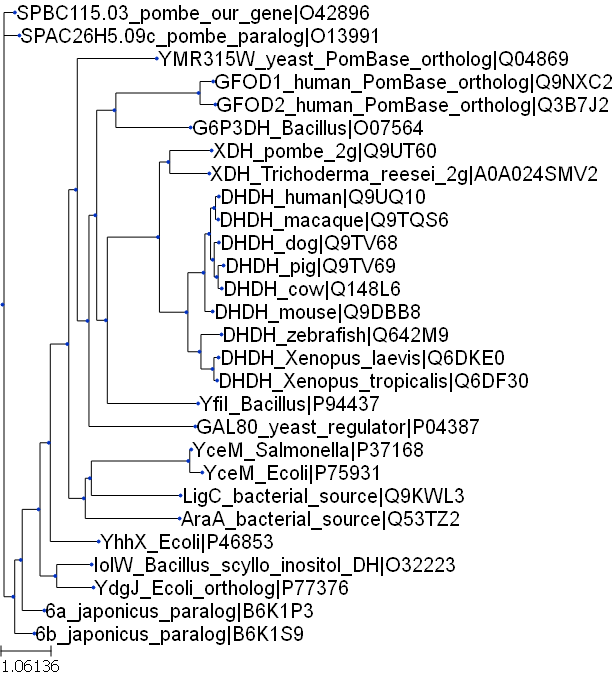

In [5]:
tree_fname = PUG_ENZYME_DIR /  "SPBC115.03" / "focused_sequences_msa_trimmed.treefile"
t = Tree(str(tree_fname), format=0)
ts = TreeStyle()
t.render('%%inline', tree_style=ts)

In [ ]:
# Download Panther Tree using API (get it from Phoebe)






In [ ]:
# Filter panther msas to only include a subset of species



In [ ]:


# B = "https://pantherdb.org/services/oai/pantherdb"

# def leaf_table(family):
#     tree = requests.get(f"{B}/treeinfo", params={"family": family}).json()
#     rows = {}
#     def walk(n):
#         if isinstance(n, dict):
#             if n.get("tree_node_type") == "LEAF":
#                 m = re.search(r"UniProtKB=(\w+)", n.get("node_name", ""))
#                 rows[n["persistent_id"]] = {
#                     "gene_symbol": n.get("gene_symbol"),
#                     "uniprot": m.group(1) if m else None,
#                     "organism": n.get("organism"),
#                     "name": n.get("definition"),
#                 }
#             for v in n.values(): walk(v)
#         elif isinstance(n, list):
#             for v in n: walk(v)
#     walk(tree)
#     return rows

# table = leaf_table("PTHR11447")
# print(table.get("PTN002479088"))

In [ ]:
y1000plus_dir = '/home/heineike/genomes/y1000plus/'
tree_fname = y1000plus_dir + '332_2408OGs_time-calibrated_phylogeny_species-names_updated.newick'
t = Tree(tree_fname)

ts = TreeStyle()
ts.show_leaf_name = False
#ts.show_branch_length = True

# for node in t.traverse():
#     if not(node.is_leaf()):
#         node_label = TextFace(node.name)
#         node.add_face(node_label, column=1, position = "branch-bottom")

# post_WGH_colors = {'low':  '#8cc3f6', # '#d3d3fe', #'#3192ff',#'#7eeaf7', ##2DD7ED',      #'#e6fcff', 
#                    'high': '#fcbba1'} #'#59E3EB'}  #'#ffebe6'}


node_color_dict = {'KLE':"#deb9f6",
                   'ZT': "YellowGreen",
                   'Post_WGH': "LightYellow",   #default color for post WGH
                   'low': '#8cc3f6',    #syntenic orthologs of low LFC ohnolog
                   'high': '#fcbba1',    #syntenic orthologs of high LFC ohnolog
                   'outgroup': 'LightGrey'
                  }


leaves_to_view = {'Yarrowia_lipolytica':('outgroup', 'Ylip'),
                  'Candida_albicans': ('outgroup','Calb'),
                'Lachancea_kluyveri': ('KLE','Lklu'),
                 'Lachancea_waltii':  ('KLE','Lwal'),
                 'Kluyveromyces_lactis': ('KLE','Klac'),
                  'Vanderwaltozyma_polyspora': ('Post_WGH','Vpol'),
                 'Naumovozyma_castellii': ('Post_WGH','Ncas'),
                 'Candida_glabrata': ('Post_WGH','Cgla'),
                 #'Saccharomyces_eubayanus': ('post_WGH','Seub'),
                 'Saccharomyces_uvarum': ('Post_WGH','Suva'),
                 'Saccharomyces_mikatae': ('Post_WGH','Smik'),
                 'Saccharomyces_cerevisiae': ('Post_WGH','Scer'),
                  'Saccharomyces_paradoxus': ('Post_WGH','Spar')
                 }

t.prune(leaves_to_view.keys())

t.ladderize()

for node in t.get_leaves():
    name = node.name
    group, abbrev = leaves_to_view[name]
    
    nstyle = NodeStyle()
    node_color = node_color_dict[group]
    nstyle['bgcolor']=node_color
    node.set_style(nstyle)
    
    node_label_face = TextFace(name + " ({})".format(abbrev)) #, fsize=16, fgcolor="black")
    node.add_face(node_label_face, column=1, position = "aligned")

fname = home_dir + 'scratch/time_tree_exp_species.svg'
t.render(fname, tree_style=ts)
t.render('%%inline', tree_style=ts)
